# Clustering Heterogeneous and Multi-View Data


1. **K-Modes**: clustering when all variables are categorical.
2. **K-Prototypes**: clustering when numerical and categorical variables coexist in one representation.
3. **Multi-view clustering**: clustering when the same objects are represented by multiple feature sets or *views*.
4. Compare three integration strategies:
   - **Early fusion**: combine features first, then cluster.
   - **Late fusion**: cluster each view independently, then obtain a consensus partition.
   - **Joint learning**: learn a clustering while the views interact during optimization.

> The class labels supplied by benchmark datasets are used **only for evaluation** (NMI/ARI). They are not used to fit any clustering model. Note: in the project the metric evaluation is not enough to evaluate the clustering results. You must always characterize and interpret the clusters.

- `kmodes` for K-Modes and K-Prototypes;
- `scikit-learn` for standard clustering, preprocessing, and evaluation;
- `mvlearn` for multi-view clustering algorithms.


%pip install kmodes mvlearn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

RANDOM_STATE = 42

def clustering_scores(y_true, y_pred):
    # External validation: labels are used only to evaluate clustering.
    return {
        "NMI": normalized_mutual_info_score(y_true, y_pred),
#         "ARI": adjusted_rand_score(y_true, y_pred),
    }
data_path = './data_notebook/data/'

# Part I — Clustering different kinds of attributes

The distinction is about the **type of attributes in one data representation**:

| Algorithm | Data | Representative |
|---|---|---|
| K-Means | numerical | mean / centroid |
| K-Modes | categorical | mode |
| K-Prototypes | mixed numerical + categorical | mean + mode |

Later, multi-view clustering will address a different question: what if the **same objects have several representations**?

https://pypi.org/project/kmodes/

## 1. K-Modes — categorical data

K-Modes replaces:

- the mean with the **mode**;
- Euclidean distance with a **categorical dissimilarity**, typically the number of mismatching attributes.

We use a tiny synthetic customer dataset containing only categorical variables.

In [2]:
df = pd.read_csv(f'{data_path}adult.csv')

In [3]:
from kmodes.kmodes import KModes

cat_cols = ['marital_status', 'native_country', 'occupation', 'race', 'relationship', 'is_male', 'workclass']

X_cat = df[cat_cols]

X_cat

,marital_status,native_country,occupation,race,relationship,is_male,workclass
0,Married-civ-spouse,United-States,Sales,White,Husband,True,Private
1,Never-married,Mexico,Farming-fishing,White,Other-relative,True,Private
2,Married-civ-spouse,United-States,Sales,Black,Husband,True,Private
3,Divorced,?,Craft-repair,White,Not-in-family,True,Private
4,Married-civ-spouse,United-States,Priv-house-serv,White,Other-relative,True,Private
...,...,...,...,...,...,...,...
36626,Divorced,United-States,Exec-managerial,White,Not-in-family,True,Private
36627,Married-civ-spouse,United-States,Other-service,White,Husband,True,Private
36628,Married-civ-spouse,United-States,Exec-managerial,White,Husband,True,Private
36629,Married-civ-spouse,United-States,Prof-specialty,Asian-Pac-Islander,Husband,True,Private


In [4]:
km = KModes(
    n_clusters=3,
    init="Huang",
    n_init=10,
    random_state=RANDOM_STATE
)

labels_kmodes = km.fit_predict(X_cat)

result_kmodes = X_cat.copy()
result_kmodes["cluster"] = labels_kmodes
result_kmodes

,marital_status,native_country,occupation,race,relationship,is_male,workclass,cluster
0,Married-civ-spouse,United-States,Sales,White,Husband,True,Private,1
1,Never-married,Mexico,Farming-fishing,White,Other-relative,True,Private,2
2,Married-civ-spouse,United-States,Sales,Black,Husband,True,Private,1
3,Divorced,?,Craft-repair,White,Not-in-family,True,Private,1
4,Married-civ-spouse,United-States,Priv-house-serv,White,Other-relative,True,Private,1
...,...,...,...,...,...,...,...,...
36626,Divorced,United-States,Exec-managerial,White,Not-in-family,True,Private,2
36627,Married-civ-spouse,United-States,Other-service,White,Husband,True,Private,1
36628,Married-civ-spouse,United-States,Exec-managerial,White,Husband,True,Private,1
36629,Married-civ-spouse,United-States,Prof-specialty,Asian-Pac-Islander,Husband,True,Private,1


In [5]:
modes = pd.DataFrame(km.cluster_centroids_, columns=X_cat.columns)
modes.index.name = "cluster"
modes

,marital_status,native_country,occupation,race,relationship,is_male,workclass
cluster,,,,,,,
0,Never-married,United-States,Adm-clerical,White,Not-in-family,False,Private
1,Married-civ-spouse,United-States,Craft-repair,White,Husband,True,Private
2,Never-married,United-States,Other-service,White,Not-in-family,True,Private


### Interpretation

Each row of `cluster_centroids_` is a **mode**:

$
Q_l = [q_{l1}, \ldots, q_{lm}]
$

For each attribute, the representative value is the most frequent category in that cluster.

The optimization seeks assignments and modes that minimize the total categorical dissimilarity between each object and its assigned mode.

## 2. K-Prototypes — mixed numerical and categorical data

K-Prototypes combines the ideas of K-Means and K-Modes.

For a mixed object $X_i$ and prototype $Q_l$, a common form of the dissimilarity is

$
d(X_i,Q_l)
=
\sum_{j\in Num}(x_{ij}-q_{lj})^2
+
\gamma
\sum_{j\in Cat}\delta(x_{ij},q_{lj}),
$

where:

- the numerical part uses squared Euclidean differences;
- the categorical part counts mismatches;
- $\gamma$ balances the two contributions.

In [6]:
from kmodes.kprototypes import KPrototypes

X_mixed = df.drop('over_threshold', axis=1)

X_mixed

,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass
0,43,0.0,0.0,10,34278,35,Married-civ-spouse,United-States,Sales,White,Husband,True,Private
1,23,0.0,0.0,3,244698,35,Never-married,Mexico,Farming-fishing,White,Other-relative,True,Private
2,39,0.0,0.0,10,118286,40,Married-civ-spouse,United-States,Sales,Black,Husband,True,Private
3,35,0.0,0.0,9,126675,46,Divorced,?,Craft-repair,White,Not-in-family,True,Private
4,66,0.0,0.0,13,28367,99,Married-civ-spouse,United-States,Priv-house-serv,White,Other-relative,True,Private
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36626,40,0.0,0.0,10,279679,45,Divorced,United-States,Exec-managerial,White,Not-in-family,True,Private
36627,40,0.0,0.0,10,323790,40,Married-civ-spouse,United-States,Other-service,White,Husband,True,Private
36628,38,0.0,0.0,10,78247,40,Married-civ-spouse,United-States,Exec-managerial,White,Husband,True,Private
36629,53,0.0,0.0,14,92565,40,Married-civ-spouse,United-States,Prof-specialty,Asian-Pac-Islander,Husband,True,Private


In [7]:
X_kproto = X_mixed.to_numpy()
categorical_cols = [6, 7, 8, 9,10, 11, 12]

kproto = KPrototypes(
    n_clusters=3,
    init="Cao",
    n_init=10,
    random_state=RANDOM_STATE,
    verbose=0
)

labels_kproto = kproto.fit_predict(
    X_kproto,
    categorical=categorical_cols
)

result_kproto = X_mixed.copy()
result_kproto["cluster"] = labels_kproto
result_kproto

,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass,cluster
0,43,0.0,0.0,10,34278,35,Married-civ-spouse,United-States,Sales,White,Husband,True,Private,2
1,23,0.0,0.0,3,244698,35,Never-married,Mexico,Farming-fishing,White,Other-relative,True,Private,0
2,39,0.0,0.0,10,118286,40,Married-civ-spouse,United-States,Sales,Black,Husband,True,Private,2
3,35,0.0,0.0,9,126675,46,Divorced,?,Craft-repair,White,Not-in-family,True,Private,2
4,66,0.0,0.0,13,28367,99,Married-civ-spouse,United-States,Priv-house-serv,White,Other-relative,True,Private,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36626,40,0.0,0.0,10,279679,45,Divorced,United-States,Exec-managerial,White,Not-in-family,True,Private,0
36627,40,0.0,0.0,10,323790,40,Married-civ-spouse,United-States,Other-service,White,Husband,True,Private,1
36628,38,0.0,0.0,10,78247,40,Married-civ-spouse,United-States,Exec-managerial,White,Husband,True,Private,2
36629,53,0.0,0.0,14,92565,40,Married-civ-spouse,United-States,Prof-specialty,Asian-Pac-Islander,Husband,True,Private,2


In [46]:
# Similar to inertia_ in scikit-learn's K-Means. Cost is total within-cluster dissimilarity
print("Cost:", kproto.cost_)

# Gamma is the relative contribution of categorical attributes. 
# Larger values --> categorical mismatches have more influence
print("Gamma:", kproto.gamma)
print("\nCluster prototypes:")
kproto.cluster_centroids_

Cost: 93761585954964.95
Gamma: 9485.435691865432

Cluster prototypes:


array([['38.5138056566788', '1073.4533183982078', '87.0241388966676',
        '10.055558667040044', '205351.12859143098', '40.38302996359563',
        'Married-civ-spouse', 'United-States', 'Craft-repair', 'White',
        'Husband', 'True', 'Private'],
       ['36.63112927191679', '1045.505014858841', '85.68369242199108',
        '9.937221396731054', '378019.21972511144', '40.24739970282318',
        'Married-civ-spouse', 'United-States', 'Craft-repair', 'White',
        'Husband', 'True', 'Private'],
       ['39.681376941457586', '1134.8270609318997', '84.50216547192353',
        '10.16726403823178', '93629.33139187575', '40.550851254480285',
        'Married-civ-spouse', 'United-States', 'Exec-managerial',
        'White', 'Husband', 'True', 'Private']], dtype='<U32')

K-Prototypes handles **heterogeneous attributes in one feature table**.

The same object may have multiple representations:

$
X^{(1)}, X^{(2)}, \ldots, X^{(V)}.
$

Examples:

- an image described by color, texture, and shape descriptors;
- a person described by demographic, behavioral, and social-network features;
- a document described by lexical and semantic embeddings.

These are **multiple views** of the same $n$ objects.

This motivates **multi-view clustering**.

# Part II — From one representation to multiple views

## 3. Three ways to integrate views

Let

$
X^{(v)} \in \mathbb{R}^{n\times d_v},
\qquad v=1,\ldots,V,
$

where all matrices contain the same $n$ objects but possibly different features.

### Early fusion

Combine the features first:

$
X = [X^{(1)} \mid X^{(2)} \mid \cdots \mid X^{(V)}]
$

and then apply an ordinary clustering algorithm.

### Late fusion

Cluster each view independently:

$
X^{(v)} \rightarrow C^{(v)}
$

and then combine the partitions:

$
C^{(1)},\ldots,C^{(V)} \rightarrow C^*.
$

The second step is a **consensus clustering** problem.

### Joint learning

The views interact while the model is being learned:

$
\{X^{(1)},\ldots,X^{(V)}\}
\rightarrow
\text{joint optimization}
\rightarrow C.
$

## 4. A real multi-view dataset: UCI Multiple Features

`mvlearn` provides the UCI handwritten digits multi-view dataset. The full dataset contains 2,000 handwritten digits: $0,1,\ldots,9$ with 200 examples of each digit. The digits were extracted from Dutch utility maps. The important part for multi-view learning is that the same handwritten digit is represented using six different feature extraction methods. Each digit is represented through several different feature sets.

We select digits 0–4 and three views. So we select only digits: $ 0,1,2,3,4 $
Since there are 200 instances per digit: $ 5\times200=1000\text{ objects} $

| `mvlearn` view |         Shape | Representation                     | Meaning                                                                                         |
| -------------- | ------------: | ---------------------------------- | ----------------------------------------------------------------------------------------------- |
| View 1         |  `(1000, 76)` | **76 Fourier coefficients**        | Capture **frequency and shape information** of the handwritten digit.                           |
| View 2         | `(1000, 216)` | **216 profile correlations**       | Capture the **spatial distribution of pixels/ink** through correlations between image profiles. |
| View 3         |  `(1000, 64)` | **64 Karhunen–Loève coefficients** | Provide a **compact, variance-based representation** of the digit, conceptually similar to PCA. |



https://mvlearn.github.io/index.html

In [8]:
from mvlearn.datasets import load_UCImultifeature

Xs, y_true = load_UCImultifeature(
    select_labeled=list(range(5)),
    views=[0, 1, 2]
)

print("Number of views:", len(Xs))
for i, X in enumerate(Xs):
    print(f"View {i+1}: {X.shape}")

print("Ground-truth labels:", np.unique(y_true))

Number of views: 3
View 1: (1000, 76)
View 2: (1000, 216)
View 3: (1000, 64)
Ground-truth labels: [0. 1. 2. 3. 4.]


Because many clustering methods depend on scale, each view is standardized **separately**.

In [9]:
Xs_scaled = [
    StandardScaler().fit_transform(X)
    for X in Xs
]

n_clusters = len(np.unique(y_true))

## 5. Single-view baselines

Before fusing anything, cluster each view independently.

This tells us how informative each representation is by itself.

In [10]:
results = {}
single_view_labels = []

for v, X in enumerate(Xs_scaled, start=1):
    labels = KMeans(
        n_clusters=n_clusters,
        n_init=20,
        random_state=RANDOM_STATE
    ).fit_predict(X)

    single_view_labels.append(labels)
    results[f"Single view {v}"] = clustering_scores(y_true, labels)

pd.DataFrame(results).T

,NMI
Single view 1,0.528264
Single view 2,0.868992
Single view 3,0.777186


# Part III — Fusion strategies

## 6. Early fusion: concatenate first, cluster second

The simplest way to use multiple views is to concatenate them:

$
X_{\text{early}}
=
[X^{(1)} \mid X^{(2)} \mid X^{(3)}].
$

After concatenation, the problem becomes an ordinary single-view clustering problem.

This is simple, but it does **not explicitly model the structure or reliability of each view**.

In [11]:
X_early = np.hstack(Xs_scaled)

labels_early = KMeans(
    n_clusters=n_clusters,
    n_init=20,
    random_state=RANDOM_STATE
).fit_predict(X_early)

results["Early fusion: concat + KMeans"] = clustering_scores(
    y_true, labels_early
)

pd.DataFrame(results).T

,NMI
Single view 1,0.528264
Single view 2,0.868992
Single view 3,0.777186
Early fusion: concat + KMeans,0.881292


## 7. Late fusion: independent clusterings → consensus clustering

With late fusion, we **do not concatenate the features**.

We already have one partition per view:

$
C^{(1)}, C^{(2)}, C^{(3)}.
$

Now we combine those partitions into a single consensus partition \(C^*\).

An important point:

> Cluster IDs themselves are arbitrary. Therefore, we should not average or vote directly on label numbers.

Consensus-clustering algorithms operate on the **partition structure** instead.

In [12]:
base_partitions = np.vstack(single_view_labels)

print("Shape:", base_partitions.shape)
print("Rows = clusterings, columns = samples")
base_partitions[:, :12]

Shape: (3, 1000)
Rows = clusterings, columns = samples


array([[1, 0, 3, 1, 3, 0, 4, 0, 3, 2, 1, 2],
       [3, 4, 3, 0, 0, 4, 0, 4, 0, 2, 3, 2],
       [2, 1, 2, 1, 1, 1, 0, 1, 0, 4, 2, 4]], dtype=int32)

### Cluster ensemble algorithms

The `ClusterEnsembles` package implements several consensus methods, including:

- **CSPA** — Cluster-based Similarity Partitioning Algorithm;
- **HGPA** — HyperGraph Partitioning Algorithm;
- **MCLA** — Meta-CLustering Algorithm;
- **HBGF** — Hybrid Bipartite Graph Formulation;
- **NMF** — non-negative matrix factorization based consensus.

They all solve the same high-level problem:

$
\{C^{(1)}, C^{(2)}, \ldots, C^{(V)}\}
\longrightarrow C^*,
$

but they construct the consensus in different ways.

Actually, `ClusterEnsembles` works only with old python versions https://pypi.org/project/ensembleclustering/.
It can be useful, since it is a collection of Cluster ensemble algorithms with paper reference.
We implemented a custom version of the algorithm.

In [13]:
from utils.ClusterEnsemblesAlgorithm import mcla_consensus

In [14]:
labels_mcla, association_matrix, meta_cluster_labels, H, G = mcla_consensus(base_partitions, n_clusters=n_clusters)

results["Late fusion: MCLA"] = clustering_scores(
    y_true,
    labels_mcla
)

pd.DataFrame(results).T.sort_values("NMI", ascending=False)

,NMI
Late fusion: MCLA,0.886245
Early fusion: concat + KMeans,0.881292
Single view 2,0.868992
Single view 3,0.777186
Single view 1,0.528264


### What is happening conceptually?

The late-fusion pipeline is:

$
X^{(1)} \rightarrow C^{(1)}, \qquad
X^{(2)} \rightarrow C^{(2)}, \qquad
X^{(3)} \rightarrow C^{(3)}
$

followed by

$
\{C^{(1)},C^{(2)},C^{(3)}\}
\rightarrow
\text{consensus algorithm}
\rightarrow
C^*.
$

Notice that the **original feature matrices are no longer needed** by the consensus step.

This is the defining feature of late fusion.

# Part IV — Joint multi-view clustering

## 8. Joint learning

Early fusion combines the views **before** clustering.

Late fusion combines the results **after** independent clustering.

Joint multi-view methods instead let the views **interact during learning**.

`mvlearn` provides several algorithms that illustrate different mechanisms:

1. **MultiviewKMeans** — a co-EM style algorithm;
2. **MultiviewSpectralClustering** — spectral clustering with iterative information exchange between views;
3. **MultiviewCoRegSpectralClustering** — encourages agreement between view-specific spectral representations through co-regularization.

These are useful examples because they show that “joint learning” is not one algorithm: it is a family of strategies.

## 9. Multi-view K-Means

`MultiviewKMeans` in `mvlearn` currently works with **two views**.

It alternates information between the two views using a co-EM framework, rather than concatenating their features.

In [15]:
from mvlearn.cluster import MultiviewKMeans

Xs_two = Xs_scaled[:2]

mv_kmeans = MultiviewKMeans(
    n_clusters=n_clusters,
    n_init=10,
    random_state=RANDOM_STATE
)

labels_mv_kmeans = mv_kmeans.fit_predict(Xs_two)

results["Joint: MultiviewKMeans (2 views)"] = clustering_scores(
    y_true, labels_mv_kmeans
)

pd.DataFrame(results).T.sort_values("NMI", ascending=False)

,NMI
Late fusion: MCLA,0.886245
Early fusion: concat + KMeans,0.881292
Single view 2,0.868992
Single view 3,0.777186
Joint: MultiviewKMeans (2 views),0.727338
Single view 1,0.528264


## 10. Multi-view spectral clustering

Spectral methods are useful when clusters are not well represented by spherical Euclidean clusters.

`MultiviewSpectralClustering` can use **two or more views**.
The implementation follows a co-training-style multi-view spectral approach: information from one view is used to refine the representation learned from the others.

In [16]:
from mvlearn.cluster import MultiviewSpectralClustering

mv_spectral = MultiviewSpectralClustering(
    n_clusters=n_clusters,
    random_state=RANDOM_STATE,
    affinity="nearest_neighbors",
    n_neighbors=10
)

labels_mv_spectral = mv_spectral.fit_predict(Xs_scaled)

results["Joint: MultiviewSpectral"] = clustering_scores(
    y_true, labels_mv_spectral
)

pd.DataFrame(results).T.sort_values("NMI", ascending=False)

,NMI
Joint: MultiviewSpectral,0.952518
Late fusion: MCLA,0.886245
Early fusion: concat + KMeans,0.881292
Single view 2,0.868992
Single view 3,0.777186
Joint: MultiviewKMeans (2 views),0.727338
Single view 1,0.528264


## 11. Co-regularized multi-view spectral clustering

A different joint strategy is **co-regularization**.

Each view has its own spectral representation, but the optimization includes a term that encourages the representations from different views to agree.

Conceptually:

$
\text{view-specific objective}
+
\lambda
\cdot
\text{cross-view agreement}.
$

The parameter $\lambda$ controls the trade-off between fitting each view individually and enforcing agreement across views.

In [17]:
from mvlearn.cluster import MultiviewCoRegSpectralClustering

mv_coreg = MultiviewCoRegSpectralClustering(
    n_clusters=n_clusters,
    v_lambda=2,
    random_state=RANDOM_STATE,
    affinity="nearest_neighbors",
    n_neighbors=10
)

labels_mv_coreg = mv_coreg.fit_predict(Xs_scaled)

results["Joint: CoReg Spectral"] = clustering_scores(
    y_true, labels_mv_coreg
)

pd.DataFrame(results).T.sort_values("NMI", ascending=False)

,NMI
Joint: CoReg Spectral,0.964451
Joint: MultiviewSpectral,0.952518
Late fusion: MCLA,0.886245
Early fusion: concat + KMeans,0.881292
Single view 2,0.868992
Single view 3,0.777186
Joint: MultiviewKMeans (2 views),0.727338
Single view 1,0.528264


# Part V — Compare the strategies

## 12. Final comparison

The purpose of this table is **not** to declare one fusion strategy universally best.

Performance depends on:

- how informative each view is;
- whether views are complementary or redundant;
- noise;
- scaling;
- cluster geometry;
- assumptions made by each algorithm.

The comparison is useful because all methods are evaluated on the **same objects**.

In [18]:
comparison = (
    pd.DataFrame(results)
    .T
    .sort_values("NMI", ascending=False)
)

comparison.round(3)

,NMI
Joint: CoReg Spectral,0.964
Joint: MultiviewSpectral,0.953
Late fusion: MCLA,0.886
Early fusion: concat + KMeans,0.881
Single view 2,0.869
Single view 3,0.777
Joint: MultiviewKMeans (2 views),0.727
Single view 1,0.528


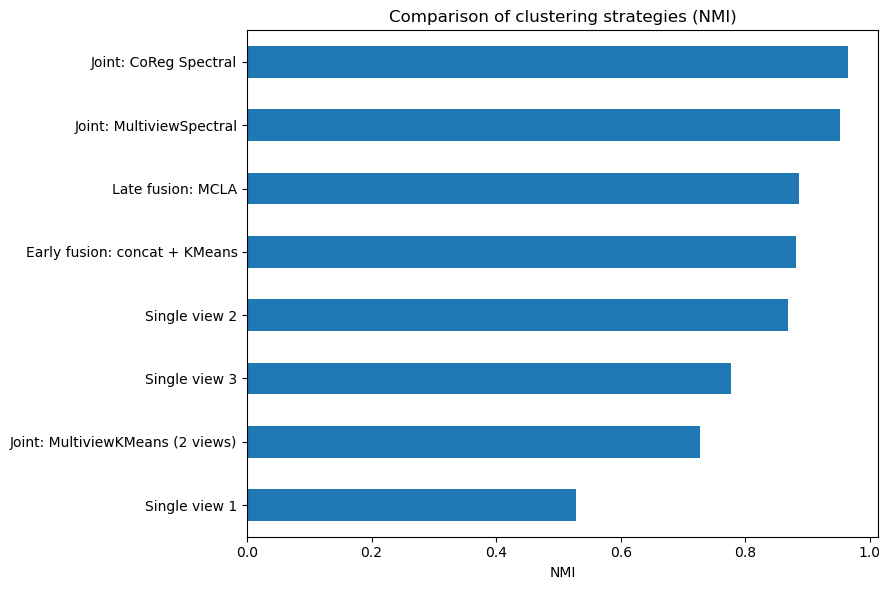

In [19]:
ax = comparison["NMI"].sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Comparison of clustering strategies (NMI)"
)
ax.set_xlabel("NMI")
plt.tight_layout()
plt.show()